Dataset loaded successfully!
Total records: 9994

Missing values:
Order Date    0
Sales         0
dtype: int64

Monthly Sales:
Order Date
2014-01-01     14236.8950
2014-02-01      4519.8920
2014-03-01     55691.0090
2014-04-01     28295.3450
2014-05-01     23648.2870
2014-06-01     34595.1276
2014-07-01     33946.3930
2014-08-01     27909.4685
2014-09-01     81777.3508
2014-10-01     31453.3930
2014-11-01     78628.7167
2014-12-01     69545.6205
2015-01-01     18174.0756
2015-02-01     11951.4110
2015-03-01     38726.2520
2015-04-01     34195.2085
2015-05-01     30131.6865
2015-06-01     24797.2920
2015-07-01     28765.3250
2015-08-01     36898.3322
2015-09-01     64595.9180
2015-10-01     31404.9235
2015-11-01     75972.5635
2015-12-01     74919.5212
2016-01-01     18542.4910
2016-02-01     22978.8150
2016-03-01     51715.8750
2016-04-01     38750.0390
2016-05-01     56987.7280
2016-06-01     40344.5340
2016-07-01     39261.9630
2016-08-01     31115.3743
2016-09-01     73410.0249
2016

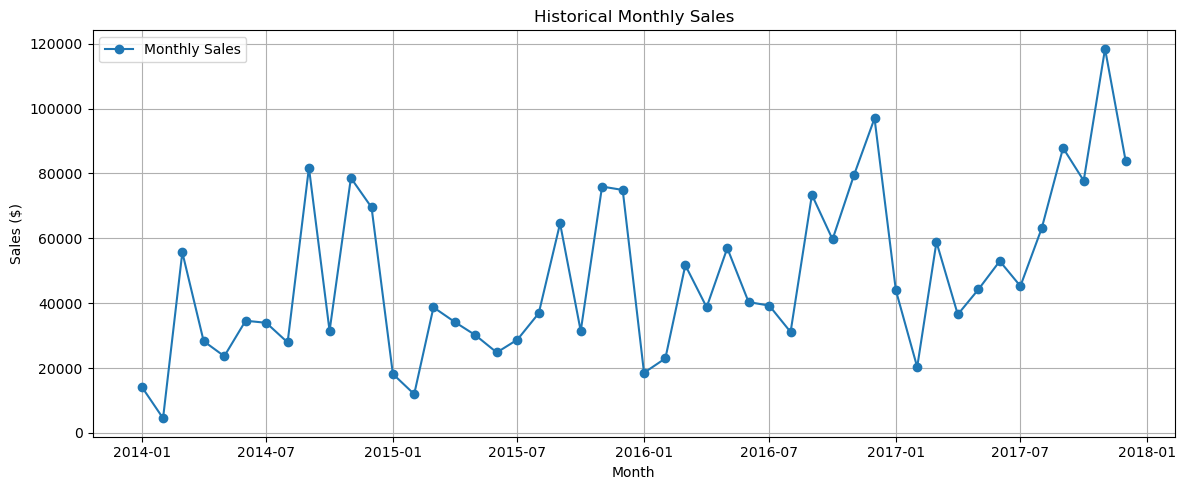

In [2]:

import pandas as pd
import matplotlib.pyplot as plt

# 1. Load dataset
df = pd.read_csv(
    "Sample - Superstore.csv",
    encoding="cp1252"
)

print("Dataset loaded successfully!")
print("Total records:", len(df))

# 2. Convert Order Date into datetime
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%m/%d/%Y"
)

# 3. Check missing values
print("\nMissing values:")
print(df[["Order Date", "Sales"]].isnull().sum())

# 4. Sort data by date
df = df.sort_values("Order Date")

# 5. Convert daily transactions into monthly sales
monthly_sales = (
    df.set_index("Order Date")["Sales"]
    .resample("MS")
    .sum()
)

# 6. Display monthly sales
print("\nMonthly Sales:")
print(monthly_sales)

# 7. Save prepared data
monthly_sales.to_csv("monthly_sales.csv")

# 8. Visualize historical sales
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    label="Monthly Sales"
)

plt.title("Historical Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.savefig("historical_sales.png")
plt.show()


Monthly sales data loaded!
Total months: 48

Training records: 33
Testing records: 12

Model training completed!

MODEL PERFORMANCE
-------------------------
MAE: 15068.29
RMSE: 18519.86
MAPE: 23.54 %


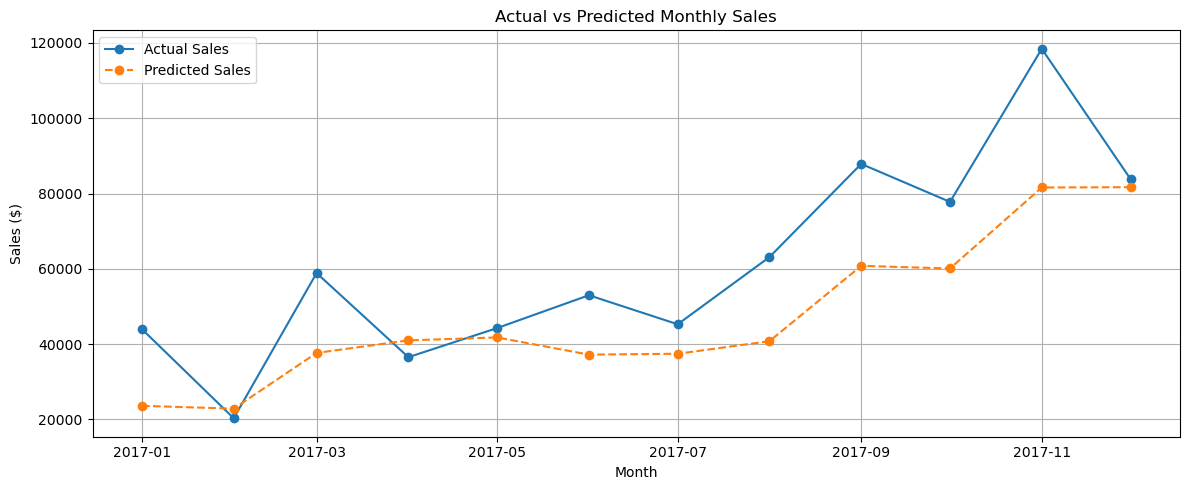


NEXT 6 MONTHS SALES FORECAST
----------------------------
     Month  Predicted Sales
2018-01-01     30813.378625
2018-02-01     34777.578957
2018-03-01     47233.707637
2018-04-01     43834.100693
2018-05-01     46597.012056
2018-06-01     47394.778418


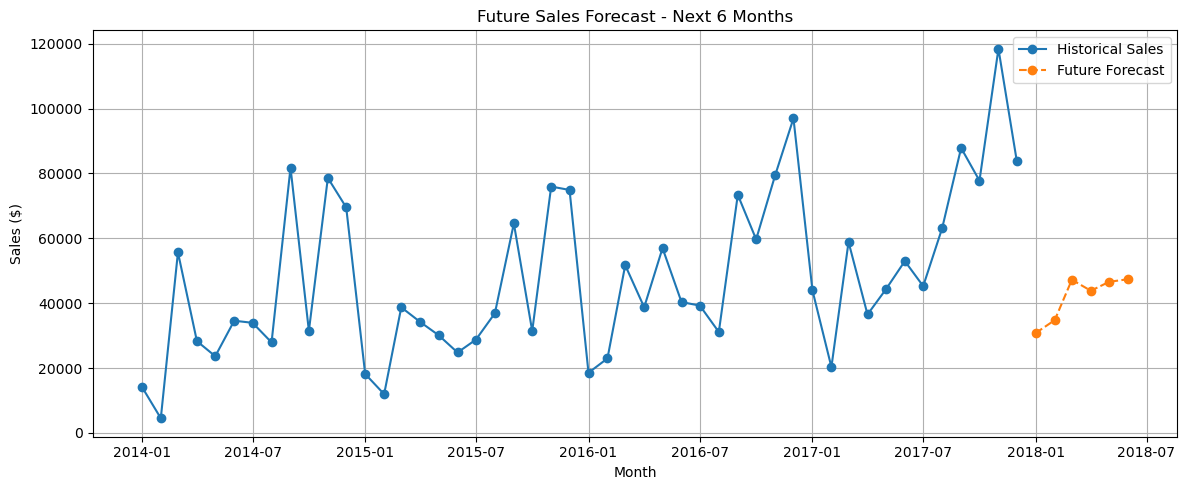


Forecasting completed successfully!
Trained model saved as sales_model.pkl


In [3]:
import numpy as np
import joblib

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

# 1. LOAD MONTHLY SALES DATA

data = pd.read_csv(
    "monthly_sales.csv",
    index_col=0,
    parse_dates=True
)

sales = data.iloc[:, 0].astype(float)
sales.index = pd.to_datetime(sales.index)

print("Monthly sales data loaded!")
print("Total months:", len(sales))

# 2. FEATURE ENGINEERING

df = pd.DataFrame(index=sales.index)

df["sales"] = sales
df["year"] = df.index.year
df["month"] = df.index.month

df["lag1"] = df["sales"].shift(1)
df["lag2"] = df["sales"].shift(2)
df["lag3"] = df["sales"].shift(3)

df["rolling_mean_3"] = (
    df["sales"].shift(1).rolling(3).mean()
)

df = df.dropna()

features = [
    "year", "month", "lag1",
    "lag2", "lag3", "rolling_mean_3"
]

X = df[features]
y = df["sales"]

# 3. CHRONOLOGICAL TRAIN-TEST SPLIT

test_size = 12

X_train = X.iloc[:-test_size]
X_test = X.iloc[-test_size:]

y_train = y.iloc[:-test_size]
y_test = y.iloc[-test_size:]

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# 4. TRAIN RANDOM FOREST MODEL

model = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)

print("\nModel training completed!")

# 5. PREDICT TEST DATA

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

mape = np.mean(
    np.abs((y_test - predictions) / y_test)
) * 100

print("\nMODEL PERFORMANCE")
print("-------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE:", round(mape, 2), "%")

# =====================================
# 6. ACTUAL VS PREDICTED GRAPH
# =====================================

plt.figure(figsize=(12, 5))

plt.plot(
    y_test.index,
    y_test.values,
    marker="o",
    label="Actual Sales"
)

plt.plot(
    y_test.index,
    predictions,
    marker="o",
    linestyle="--",
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("actual_vs_predicted.png")
plt.show()

# 7. FUTURE SALES FORECAST

# Train final model using all available data
final_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    random_state=42
)

final_model.fit(X, y)

# Save trained model
joblib.dump(final_model, "sales_model.pkl")

# Historical values used for recursive forecasting
history = list(sales.values)

future_dates = []
future_predictions = []

last_date = sales.index[-1]

for i in range(1, 7):

    next_date = last_date + pd.DateOffset(months=i)

    lag1 = history[-1]
    lag2 = history[-2]
    lag3 = history[-3]

    rolling_mean = np.mean(history[-3:])

    input_data = pd.DataFrame([{
        "year": next_date.year,
        "month": next_date.month,
        "lag1": lag1,
        "lag2": lag2,
        "lag3": lag3,
        "rolling_mean_3": rolling_mean
    }])

    prediction = final_model.predict(input_data[features])[0]

    history.append(prediction)

    future_dates.append(next_date)
    future_predictions.append(prediction)

# 8. DISPLAY FUTURE FORECAST

forecast_df = pd.DataFrame({
    "Month": future_dates,
    "Predicted Sales": future_predictions
})

print("\nNEXT 6 MONTHS SALES FORECAST")
print("----------------------------")
print(forecast_df.to_string(index=False))

forecast_df.to_csv(
    "future_sales_forecast.csv",
    index=False
)

# 9. FUTURE FORECAST GRAPH

plt.figure(figsize=(12, 5))

plt.plot(
    sales.index,
    sales.values,
    label="Historical Sales",
    marker="o"
)

plt.plot(
    future_dates,
    future_predictions,
    label="Future Forecast",
    marker="o",
    linestyle="--"
)

plt.title("Future Sales Forecast - Next 6 Months")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("future_sales_forecast.png")
plt.show()

print("\nForecasting completed successfully!")
print("Trained model saved as sales_model.pkl")
